In [40]:
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt

import Minimal_Model_1D as M

In [41]:
###defining constants##

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

checking convergence for width of 100 nm

In [58]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


In [59]:
K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, epsilon=0)
    H = D.H_sys(PHI, so='li')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

0
5
10
15
20
25


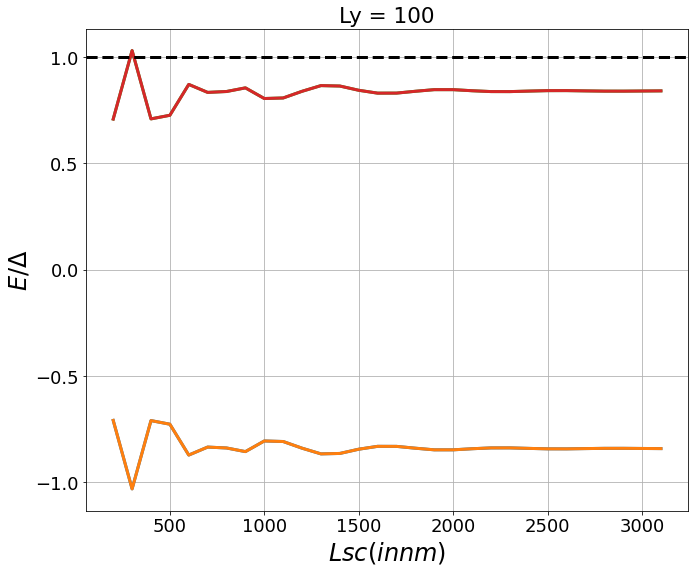

In [62]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [64]:
Ep2 = Ep[:,3]

In [67]:

for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.8341473685815576
700 5
0.8053520999652353
1000 8
0.8661011385789973
1300 11
0.8306239512832232
1600 14
0.8308148385635077
1700 15
0.8394223200900224
1800 16
0.8470584871167273
1900 17
0.84705730453402
2000 18
0.8419436850939478
2100 19
0.8380182104283508
2200 20
0.837878066002054
2300 21
0.8402726670980439
2400 22
0.84242546939217
2500 23
0.8425591436296987
2600 24
0.8412430825452806
2700 25
0.8401061906642775
2800 26
0.8400056847049594
2900 27
0.8406577002704892
3000 28


Checking convergence for width of 10 nm

In [69]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

first subband energy = 132.63440267269596 
 second subband energy = 265.2688053453919


0
5
10
15
20
25


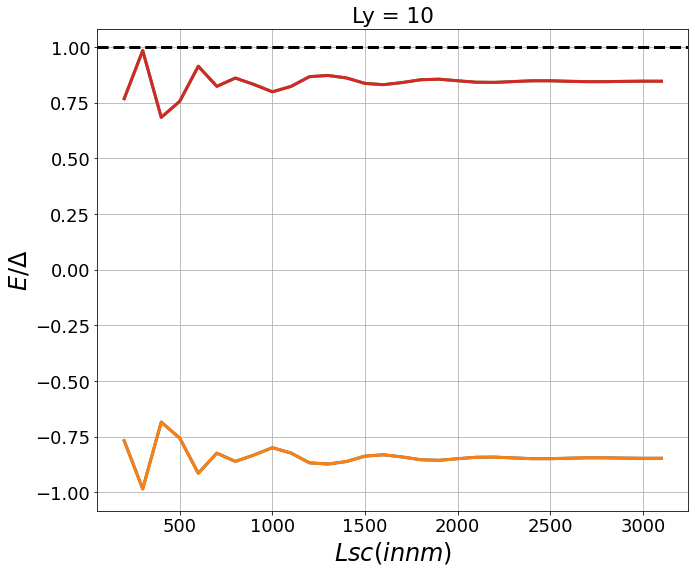

In [70]:
K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, epsilon=0)
    H = D.H_sys(PHI, so='li')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)


plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [71]:
Ep2 = Ep[:,3]


for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.8674630396842481
1200 10
0.8372006882827012
1500 13
0.8314848450652973
1600 14
0.8535653590861477
1800 16
0.8561658248527038
1900 17
0.8490393721195459
2000 18
0.8425646103149665
2100 19
0.8418484824364789
2200 20
0.8454177348977854
2300 21
0.8488585459207754
2400 22
0.8489603595980127
2500 23
0.8467095233868672
2600 24
0.8449867590956326
2700 25
0.8450869888524927
2800 26
0.8463062625234913
2900 27
0.8471995455579445
3000 28


Convergence lengths for linear SO of 20 meV-nm, weak link length of 300 nm and chemical potential of 1+OMEGA meV is:
for Ly = 100 nm ~ 1600 nm SC on both sides
for Ly = 10 nm ~ 1500 nm of SC on both sides

Now plotting E vs phi ABS for linear SO of 20 meV nm and weak link length 300 nm 

In [72]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands



first subband energy = 132.63440267269596 
 second subband energy = 265.2688053453919


In [73]:

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    #DELTA = np.array([1,0,1*cmath.exp(1j*PHI[i])])
    
    H = D.H_sys(PHI[i], so='li' )
    #print(i)
    #+ KxSq(N, M, AX, PX, KX[i])
    #H = KxSqKy(N,M,AX,AY,PX,PY,KX[i],KY[i])
    #H = H.toarray()
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    #print('a')
    #print(E.shape)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)


0
20
40
60
80
100


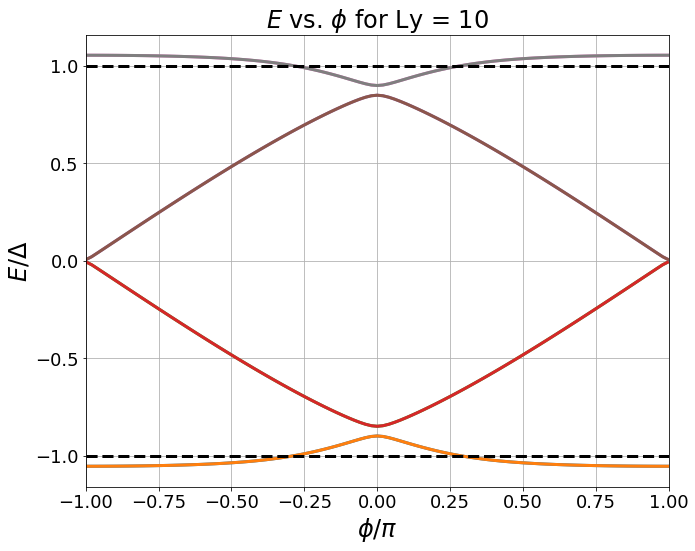

In [74]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
0
20
40
60
80
100


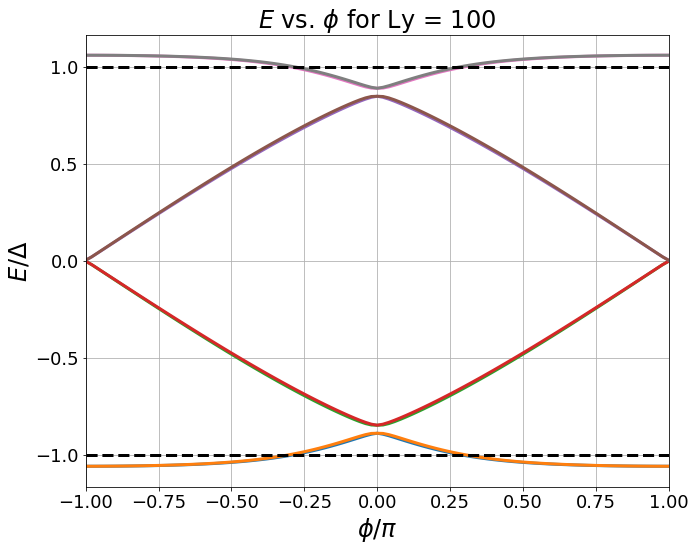

In [75]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands


PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    #DELTA = np.array([1,0,1*cmath.exp(1j*PHI[i])])
    
    H = D.H_sys(PHI[i], so='li' )
    #print(i)
    #+ KxSq(N, M, AX, PX, KX[i])
    #H = KxSqKy(N,M,AX,AY,PX,PY,KX[i],KY[i])
    #H = H.toarray()
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    #print('a')
    #print(E.shape)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

Now looking at the perturbative regime for linear SO coupling

In [77]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

ALPHAT = np.linspace(1, 100, 81)

K = 12

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)


first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


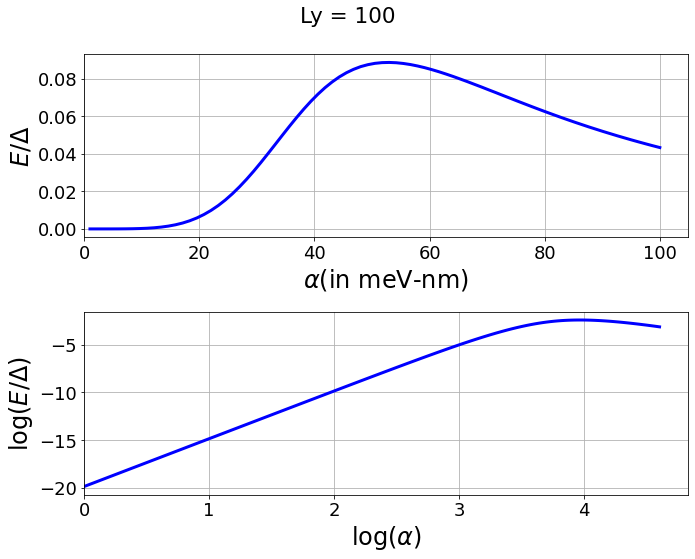

In [78]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [79]:
np.exp(3)


20.085536923187668

first subband energy = 132.63440267269596 
 second subband energy = 265.2688053453919
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


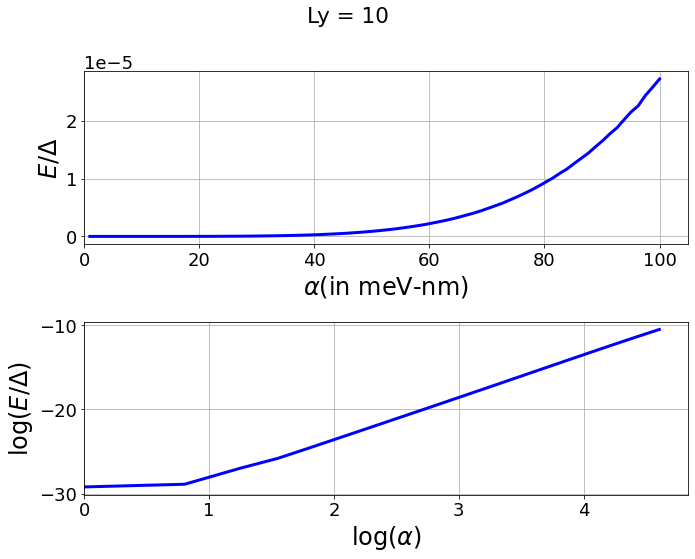

In [80]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 10           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

ALPHAT = np.linspace(1, 100, 81)

K = 12

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [81]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 1 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 1 + OMEGA

K = 12

Ep_li = np.empty((LY.shape[0],K))
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


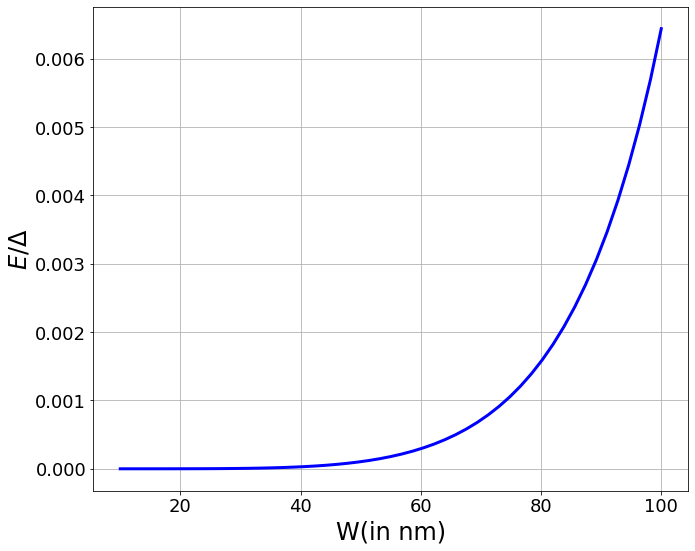

In [84]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red']

#Ep_inner = Ep[:,4:6]
Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]
#Ep_Split_cu = Ep_cu[:,7] - Ep_cu[:,6]
#Ep_lin_inner = Ep_lin[:,2:6]

#for i in range(Ep_Split.shape[1]):
#plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')
#plt.plot(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle =':' , color='red')
#plt.plot(PHI/np.pi, Ep_lin_inner[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(0.5, 1.5)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
#plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()